## Adição de ruído sobre o sinal
Este caderno descreve como é feita a adição de ruído sobre o sinal GRE simulado. 

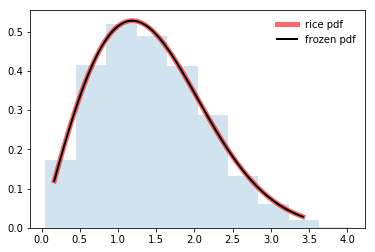

In [1]:
#bibliotecas para incializar
# -*- coding: utf-8 -*-
from scipy.stats import rice
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

#Calculate a few first moments:
b = 0.8
mean, var, skew, kurt = rice.stats(b, moments='mvsk')

#Display the probability density function (pdf):
x = np.linspace(rice.ppf(0.01, b),
rice.ppf(0.99, b), 100)
ax.plot(x, rice.pdf(x, b),'r-', lw=5, alpha=0.6, label='rice pdf')

#Alternatively, freeze the distribution and display the frozen pdf:
rv = rice(b)
ax.plot(x, rv.pdf(x), 'k-', lw=2, label='frozen pdf')

#Check accuracy of cdf and ppf:
vals = rice.ppf([0.001, 0.5, 0.999], b)
np.allclose([0.001, 0.5, 0.999], rice.cdf(vals, b))
True

#Generate random numbers:
r = rice.rvs(b, size=1000)

#And compare the histogram:
ax.hist(r, normed=True, histtype='stepfilled', alpha=0.2)
ax.legend(loc='best', frameon=False)
plt.show()


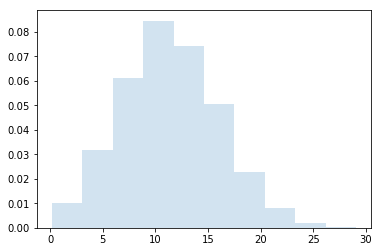

In [55]:
#bibliotecas para incializar
# -*- coding: utf-8 -*-
from scipy.stats import rice
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

b = 20

#Generate random numbers:
r = rice.rvs(2, 0, 5, size=8000)

#And compare the histogram:
ax.hist(r, normed=True, histtype='stepfilled', alpha=0.2)
plt.show()




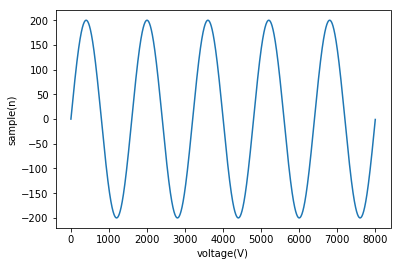

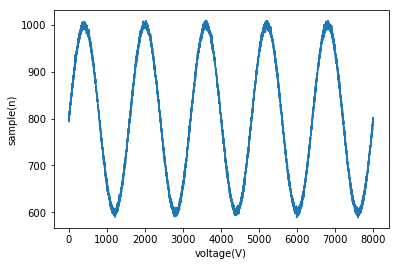

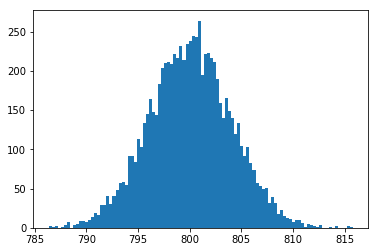

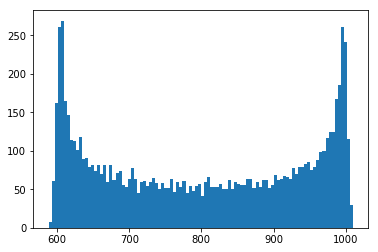

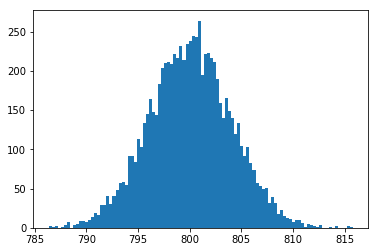

In [75]:
#gerar senoide
import matplotlib.pyplot as plt
import numpy as np

b = 415
sd = 1.77
Fs = 8000
f = 5
sample = 8000
x = np.arange(sample)
y = 200*np.sin(2 * np.pi * f * x/Fs )
plt.plot(x, y)
plt.xlabel('voltage(V)')
plt.ylabel('sample(n)')
plt.show()

#contaminar senoide
Fs = 8000
f = 5
sample = 8000
r = rice.rvs(200, 0, 4, size=sample)
x = np.arange(sample)
y2 = 200*np.sin(2 * np.pi * f * x / Fs) + r
plt.plot(x, y2)
plt.xlabel('voltage(V)')
plt.ylabel('sample(n)')
plt.show()

plt.hist(y2, bins=100)
plt.show()

plt.hist(r, bins=100)
plt.show()

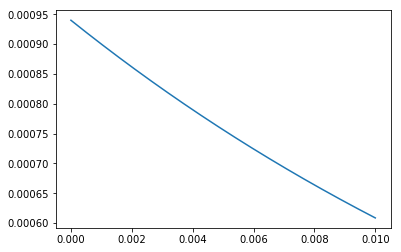

In [4]:
TE = np.linspace(0,0.010,1000)
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
y = np.array(np.absolute(0.1*0.2*0.047*np.exp(-TE/0.023)*np.exp(2.0*np.pi*1j*1.3*magField*hydroGyro/1e6*TE))) #0.1 é p/ escala       
plt.plot(TE,y)

plt.show()

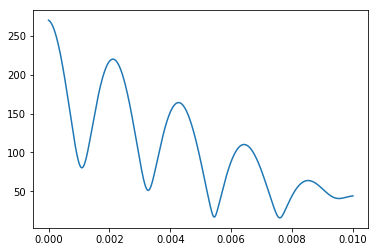

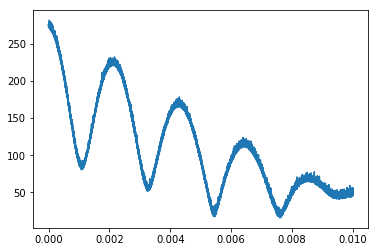

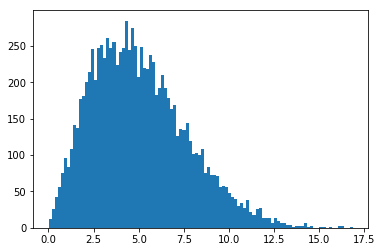

In [87]:
TE = np.linspace(0,0.010,10000)
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
y = 90*np.array(abs(1*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*1.3*magField*hydroGyro/1e6*TE)+
                 1*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*4.7*magField*hydroGyro/1e6*TE)+
                1*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*0.9*magField*hydroGyro/1e6*TE)))
plt.plot(TE,y)
plt.show()

r = rice.rvs(0, 0, 4, 10000)

y2 = y+r
plt.plot(TE,y2)
plt.show()

plt.hist(r, bins=100)
plt.show()